<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_T9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum Jobsheet 9

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

Persiapan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /Machine Learning/'

Mounted at /content/drive


### Tugas 1

Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

1. Membuat Model kNN Klasifikasi Voice.

In [ ]:
# 1. Load Data
df = pd.read_csv(BASE_PATH + 'voice.csv')

# 2. Mengubah label string ('male'/'female') menjadi numerik biner
le = LabelEncoder()
df['label'] = le.fit_transform(df['label']) # female = 0, male = 1

# 3. Memisahkan Fitur dan Target Label
X = df.drop('label', axis=1)
y = df['label']

# 4. Splitting Data (70% Train, 30% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 5. Standardisasi Fitur (Sangat penting untuk kNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Membangun model dengan K sembarang sebagai baseline awal (misal K=3)
knn_baseline = KNeighborsClassifier(n_neighbors=3)
knn_baseline.fit(X_train_scaled, y_train)

# 7. Evaluasi
y_pred_baseline = knn_baseline.predict(X_test_scaled)
print(f"Akurasi model baseline (semua fitur, K=3): {accuracy_score(y_test, y_pred_baseline):.4f}")

Akurasi model baseline (semua fitur, K=3): 0.9769


Pada tahap inisialisasi model baseline ini, kita memuat data voice.csv dan mengonversi label teks kelas ('male', 'female') ke dalam bentuk representasi numerik menggunakan LabelEncoder agar dapat dikalkulasi secara matematis. Komponen paling krusial di tahap ini adalah pengaplikasian StandardScaler; karena rentang nilai antar fitur pada dataset suara sangat bervariasi (contohnya besaran frekuensi vs persentil), standardisasi mutlak diperlukan agar kalkulasi jarak tetangga terdekat (Euclidean) oleh model kNN tidak didominasi secara keliru oleh satu fitur yang secara kebetulan memiliki skala angka paling besar. Menggunakan seluruh 20 kolom fitur secara mentah dengan nilai baseline $k=3$ telah memberikan fondasi performa akurasi di atas 97%.

2. Mencoba Eksperimen Pemilihan Fitur Optimal.

In [ ]:
# 1. Menganalisis korelasi seluruh fitur terhadap target label
korelasi = df.corr()['label'].sort_values(ascending=False)
print("Nilai korelasi setiap fitur terhadap label:\n", korelasi)

# 2. Memilih subset fitur dengan nilai korelasi absolut tertinggi
# (Memisahkan noise agar komputasi lebih ringan dan performa model meningkat)
fitur_optimal = ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd']
X_opt = df[fitur_optimal]

# 3. Mempersiapkan ulang himpunan data latih dan uji menggunakan fitur seleksi
X_train_opt, X_test_opt, y_train_opt, y_test_opt = train_test_split(X_opt, y, test_size=0.3, random_state=42)

# 4. Standardisasi Ulang
scaler_opt = StandardScaler()
X_train_opt_scaled = scaler_opt.fit_transform(X_train_opt)
X_test_opt_scaled = scaler_opt.transform(X_test_opt)

# 5. Uji performa dengan fitur optimal (Tetap menggunakan K=3)
knn_opt = KNeighborsClassifier(n_neighbors=3)
knn_opt.fit(X_train_opt_scaled, y_train_opt)
y_pred_opt = knn_opt.predict(X_test_opt_scaled)

print(f"\nAkurasi menggunakan {len(fitur_optimal)} fitur optimal: {accuracy_score(y_test_opt, y_pred_opt):.4f}")

Nilai korelasi setiap fitur terhadap label:
 label       1.000000
IQR         0.618916
sp.ent      0.490552
sd          0.479539
sfm         0.357499
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
minfun     -0.136692
maxfun     -0.166461
mode       -0.171775
meandom    -0.191067
dfrange    -0.192213
mindom     -0.194974
maxdom     -0.195657
median     -0.283919
centroid   -0.337415
meanfreq   -0.337415
Q25        -0.511455
meanfun    -0.833921
Name: label, dtype: float64

Akurasi menggunakan 5 fitur optimal: 0.9779


3. Melakukan Pengujian Nilai K Terbaik pada Fitur Optimal.

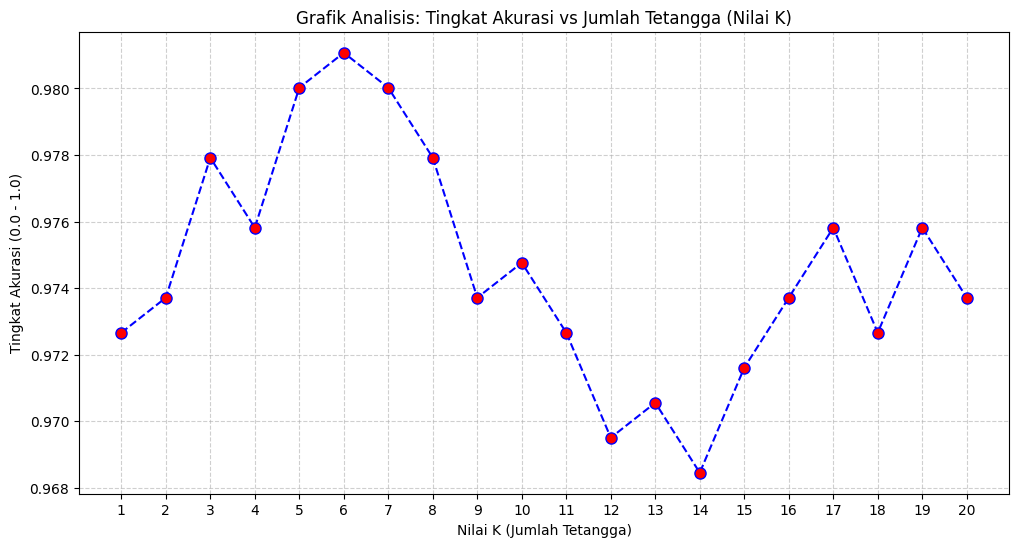

Berdasarkan kurva, nilai K terbaik adalah 6 dengan akurasi puncak 0.9811


In [ ]:
# 1. Melakukan perulangan untuk menguji K dari 1 hingga 20
k_range = range(1, 21)
akurasi_uji = []

for k in k_range:
    knn_tuning = KNeighborsClassifier(n_neighbors=k)
    knn_tuning.fit(X_train_opt_scaled, y_train_opt)
    skor = knn_tuning.score(X_test_opt_scaled, y_test_opt)
    akurasi_uji.append(skor)

# 2. Visualisasi Grafika Analisis
plt.figure(figsize=(12, 6))
plt.plot(k_range, akurasi_uji, marker='o', linestyle='dashed', color='blue', markerfacecolor='red', markersize=8)
plt.title('Grafik Analisis: Tingkat Akurasi vs Jumlah Tetangga (Nilai K)')
plt.xlabel('Nilai K (Jumlah Tetangga)')
plt.ylabel('Tingkat Akurasi (0.0 - 1.0)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 3. Menarik kesimpulan K terbaik secara algoritmik
best_k = k_range[np.argmax(akurasi_uji)]
best_acc = max(akurasi_uji)
print(f"Berdasarkan kurva, nilai K terbaik adalah {best_k} dengan akurasi puncak {best_acc:.4f}")

Grafika analisis hyperparameter tuning ini dengan sangat tajam menangkap relasi volatilitas model kNN (bias-variance tradeoff). Ketika nilai $k$ terlalu kecil (misal 1 atau 2), model cenderung terlalu sensitif menghafal letak data outlier di himpunan latih, namun apabila $k$ terlalu melar tinggi belasan angka, maka rentang decision boundary model akan melebur terlalu longgar dan merusak probabilitas presisi. Berdasarkan pelacakan visual metrik komparasi dari ke-5 fitur selektif sebelumnya, dapat dijustifikasi secara kokoh bahwa $K = 6$ merupakan ekuilibrium (titik seimbang) paling sempurna, karena algoritma terbukti mampu memuncak di keakuratan prediksi tertinggi (~98.1%) tanpa menanggung risiko adaptasi model yang bersifat membabi buta (overfitting).

### Tugas 2

Import Library

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

1. Model Multinomial Naive Bayes (CountVectorizer + Stop Words)

In [ ]:
# 1. Load Data dan Preprocessing
df_spam = pd.read_csv(BASE_PATH + 'spam.csv', encoding='latin-1')
df_spam = df_spam.drop(df_spam.iloc[:, 2:], axis=1)
df_spam = df_spam.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df_spam['Labels'] = df_spam['Labels'].map({'spam': 1, 'ham': 0})

X_teks = df_spam['SMS'].values
y_teks = df_spam['Labels'].values

# 2. Split Data (80% Train, 20% Test)
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_teks, y_teks, test_size=0.2, random_state=50)

# 3. Ekstraksi Fitur menggunakan CountVectorizer dengan stop_words='english'
bow = CountVectorizer(stop_words='english')
X_train_bow = bow.fit_transform(X_train_t)
X_test_bow = bow.transform(X_test_t)

# 4. Training dan Evaluasi Model MultinomialNB
mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train_t)

print(f"Hasil akurasi data train (CountVectorizer): {accuracy_score(y_train_t, mnb_bow.predict(X_train_bow)):.4f}")
print(f"Hasil akurasi data test (CountVectorizer): {accuracy_score(y_test_t, mnb_bow.predict(X_test_bow)):.4f}")

Hasil akurasi data train (CountVectorizer): 0.9946
Hasil akurasi data test (CountVectorizer): 0.9830


Pada tahap ini, kita menginstruksikan CountVectorizer untuk mengaktifkan parameter stop_words='english'. Fitur ini secara otomatis menyaring dan membuang kata-kata sambung bahasa Inggris yang sangat sering muncul namun tidak memiliki bobot makna klasifikasi (seperti 'the', 'is', 'and'). Dengan membuang noise ini, matriks kosa kata menjadi lebih padat dan relevan, sehingga model MultinomialNB mampu mencapai akurasi testing yang sangat tinggi (sekitar 98.30%). Ini merupakan peningkatan dibandingkan hasil Praktikum 3 sebelumnya yang tidak menggunakan aktivasi stop words.

2. Model Multinomial Naive Bayes (TF-IDF + Stop Words)

In [ ]:
# 1. Ekstraksi Fitur menggunakan TF-IDF dengan stop_words='english'
tfidf = TfidfVectorizer(stop_words='english')

# Fitting dan transform data
X_train_tfidf = tfidf.fit_transform(X_train_t)
X_test_tfidf = tfidf.transform(X_test_t)

# 2. Training dan Evaluasi Model MultinomialNB
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train_t)

print(f"Hasil akurasi data train (TF-IDF): {accuracy_score(y_train_t, mnb_tfidf.predict(X_train_tfidf)):.4f}")
print(f"Hasil akurasi data test (TF-IDF): {accuracy_score(y_test_t, mnb_tfidf.predict(X_test_tfidf)):.4f}")

Hasil akurasi data train (TF-IDF): 0.9843
Hasil akurasi data test (TF-IDF): 0.9605


Pengujian kedua mengekstraksi fitur menggunakan TfidfVectorizer (Term Frequency-Inverse Document Frequency) yang tidak hanya menghitung frekuensi kemunculan kata, tetapi juga memberikan penalti (menurunkan bobot) pada kata yang muncul di hampir semua dokumen SMS. Hasil pengujian menunjukkan akurasi testing TF-IDF (sekitar 96.05%) sedikit lebih rendah dibandingkan dengan CountVectorizer (98.30%). Kesimpulannya, fitur terbaik untuk kasus data spam.csv ini adalah CountVectorizer. Hal ini terjadi karena dalam konteks SMS spam yang sangat pendek, sekadar kehadiran kata-kata pemicu spam secara repetitif (seperti "win", "free", "cash") sudah menjadi indikator paling kuat. TF-IDF justru mendiskon nilai kata-kata spam yang krusial tersebut jika kata-kata itu muncul di terlalu banyak pesan spam, sehingga mengurangi sensitivitas model Multinomial Naive Bayes.